In [1]:
from math import floor
from sonpy import lib as sp
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import seaborn as sns
import neurokit2 as nk
import tempfile
import yaml

from spike_extraction_trim import spike_extraction, spike_extraction_df


In [2]:
def gastric_stethoscope_clean_plot(df, output_yaml_path, save_dir, figsize=(20, 6)):
    try:        
        #Load channel data
        signal_data = df['stethoscope_amplitude'].dropna().values  # Get channel data, dropping NaNs
        
        #Load sample rate from yaml file
        with open(output_yaml_path, 'r') as file:
            config = yaml.safe_load(file)
        sample_rate = config['stethoscope']['sampling_rate']
        
        
        ## FILTERING
        # Apply a notch filter at 50 Hz to remove mains interference
        nyquist = 0.5 * sample_rate
        notch_freq = 50.0
        notch_w0 = notch_freq / nyquist
        b_notch, a_notch = signal.iirnotch(notch_w0, Q=30)  # Quality factor of 30
        notched_signal = signal.filtfilt(b_notch, a_notch, signal_data)
    
        # Bandpass filter specifications (100 Hz to 500 Hz)
        low = 100
        high = 499
        b, a = signal.butter(3, [low, high], btype='bandpass', fs=sample_rate, analog=False)
        notched_butter_signal = signal.filtfilt(b, a, notched_signal)
        
        # Remove the mean from the cleaned signal
        notched_butter_demean_signal = notched_butter_signal - np.mean(notched_butter_signal)
    
        df['stethoscope_amplitude_clean'] = notched_butter_demean_signal
        cleaned_file_name = save_dir + 'GASTRIC_stethoscope_cleaned_channel_data.tsv'
        df.to_csv(cleaned_file_name, sep = '\t', index=False)
        #print(df)
        
        # Task markers (these come from the 'markers' column)
        task_markers = {
            'LIVE START': 'live_start_end',
            'LIVE END': 'live_start_end',
            'REC START': 'rec_start_end',
            'REC END': 'rec_start_end',
            'START TASK': 'task_start',
            'END TASK': 'task_end',
            'QUESTION': 'question',
        }
        
        # Map markers in 'markers' column to task categories
        df['category'] = df['markers'].map(task_markers).fillna('other')
        
        # Filter out 'other' categories (for tasks)
        filtered_df = df[df['category'] != 'other']
        
        # Identify intervals for shading
        shading_intervals = {'live_start_end': [], 'rec_start_end': []}
        
        start_markers = {'live_start_end': 'LIVE START', 'rec_start_end': 'REC START'}
        end_markers = {'live_start_end': 'LIVE END', 'rec_start_end': 'REC END'}
        
        for category, start_marker in start_markers.items():
            end_marker = end_markers[category]
            
            # Find start and end times for each category
            starts = filtered_df[filtered_df['markers'] == start_marker]['time_since_start_min']
            ends = filtered_df[filtered_df['markers'] == end_marker]['time_since_start_min']
            
            # Pair start and end times for shading
            shading_intervals[category] = list(zip(starts, ends))
        
        # Marker positions for tasks and questions
        marker_positions = list(filtered_df['time_minutes'])
        
        # Plot
        plt.figure(figsize = figsize)
        plt.title('Original vs Cleaned Stethoscope Data')
        plt.xlabel('Time (minutes)')
        plt.ylabel('Amplitude')
        
        # Add transparent shading for intervals
        color_map = {
            'live_start_end': '#3e3e3e',
            'rec_start_end': '#a1a1a1',
            'question': 'grey',
            'task_start': 'black',  
            'task_end': 'black'   
        }
        
        for category, intervals in shading_intervals.items():
            for start, end in intervals:
                plt.axvspan(start, end, color=color_map[category], alpha=0.2)
        
        # Add vertical lines for task markers
        for _, row in filtered_df.iterrows():
            if row['category'] == 'question':
                plt.axvline(x=row['time_since_start_min'], color=color_map['question'], linestyle='--', alpha=0.7, linewidth=1.5)
        
        # Plot the original and cleaned signal
        plt.plot(df['time_since_start_min'].dropna().values, df['stethoscope_amplitude'].dropna().values, label='Original Signal', color='#ceebc7', alpha=0.6, lw=1.0)
        plt.plot(df['time_since_start_min'], notched_butter_demean_signal, label='Filtered Signal', color='#51C151', alpha=1.0, lw=0.2)
        plt.xlim(min(marker_positions), max(marker_positions))
        plt.ylim(min(df['stethoscope_amplitude'].dropna().values), max(df['stethoscope_amplitude'].dropna().values))

        #legend
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.append(plt.Line2D([0], [0], color=color_map['live_start_end'], lw=2, label='LIVE START/END'))
        handles.append(plt.Line2D([0], [0], color=color_map['rec_start_end'], lw=2, label='REC START/END'))
        handles.append(plt.Line2D([0], [0], color=color_map['question'], linestyle='--', lw=2, label='QUESTION'))
        labels.append('LIVE START/END')
        labels.append('REC START/END')
        labels.append('QUESTION')
        plt.legend(handles=handles, labels=labels, loc='upper left', bbox_to_anchor=(1, 1))
        
        plt.tight_layout()

        plt_name = 'GASTRIC_stethoscope.png'
        plt_save_path = save_dir +  '/'+ plt_name
        plt.savefig(plt_save_path, dpi=300, bbox_inches='tight')
        #plt.show()

        return df, plt_save_path

    except Exception as e:
        # Handle exception and create fallback image
        print(f"An error occurred: {e}")
        df = df
        plt_name = 'GASTRIC_stethoscope.png'

        # Create FAILED figure with green shading
        plt.figure(figsize=figsize, facecolor='white')
        plt.gca().set_facecolor('white')
        plt.text(0.5, 0.5, f"Data to produce {plt_name} not found",
                 fontsize=14, ha='center', va='center', color='#ceebc7')

        # Save the fallback image
        fallback_path = 'GASTRICstethoscope_FAIL_image.png'
        plt_save_path = save_dir +  '/' + fallback_path
        plt.axis('off') 
        plt.savefig(plt_save_path, bbox_inches='tight', facecolor='white')
    
        return df, plt_save_path

In [3]:
task = 'GASTRIC'
spike_file = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_21_02/physio/sub-063_gastric.smrx'
save_dir = '/Users/hsavage/OneDrive - University College London/Manuscripts/Gastric_task/Gastric_21_02/physio/extracted/'
participant_id = '063'

trimmed_df, output_yaml_path = spike_extraction_df(task,participant_id, spike_file, save_dir)

print(trimmed_df)
print(output_yaml_path)
df, plt_save_path = gastric_stethoscope_clean_plot(trimmed_df, participant_id, output_yaml_path, save_dir)

ValueError: max() arg is an empty sequence

In [81]:
def gastric_compute_freq(df, save_dir, figsize=(20,4)):
    try:
        
        #Load channel data
        signal_data = df['stethoscope_amplitude_clean']
        
        # Compute the FFT
        fft_result = np.fft.fft(signal_data)
        
        # Compute the frequencies corresponding to the FFT
        frequencies = np.fft.fftfreq(len(signal_data), d=0.001)  # d= sampling interval
        
        # Compute the amplitude spectrum
        amplitude = np.abs(fft_result)
        
        # Plot frequency vs. amplitude
        plt.figure(figsize=figsize)
        plt.plot(frequencies[:len(frequencies)//2], amplitude[:len(frequencies)//2], lw = 0.2, color='#51C151')  # Plot only positive frequencies
        plt.title("Frequency vs Amplitude")
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Amplitude")
        plt.grid()
        
        plt.tight_layout()

        plt_name = 'GASTRIC_stethoscope_freq.png'
        plt_save_path = save_dir +  '/'+ plt_name
        plt.savefig(plt_save_path, dpi=300, bbox_inches='tight')
        #plt.show()

    
    except Exception as e:
        # Handle exception and create fallback image
        print(f"An error occurred: {e}")
        
        plt_name = 'GASTRIC_stethoscope_freq.png'

        # Create FAILED figure with green shading
        plt.figure(figsize=figsize, facecolor='white')
        plt.gca().set_facecolor('white')
        plt.text(0.5, 0.5, f"Data to produce {plt_name} not found",
                 fontsize=14, ha='center', va='center', color='#ceebc7')

        # Save the fallback image
        fallback_path = 'GASTRIC_stethoscope_freq_FAIL_image.png'
        plt_save_path = save_dir +  '/' + fallback_path
        plt.axis('off') 
        plt.savefig(plt_save_path, bbox_inches='tight', facecolor='white')
    
        return plt_save_path

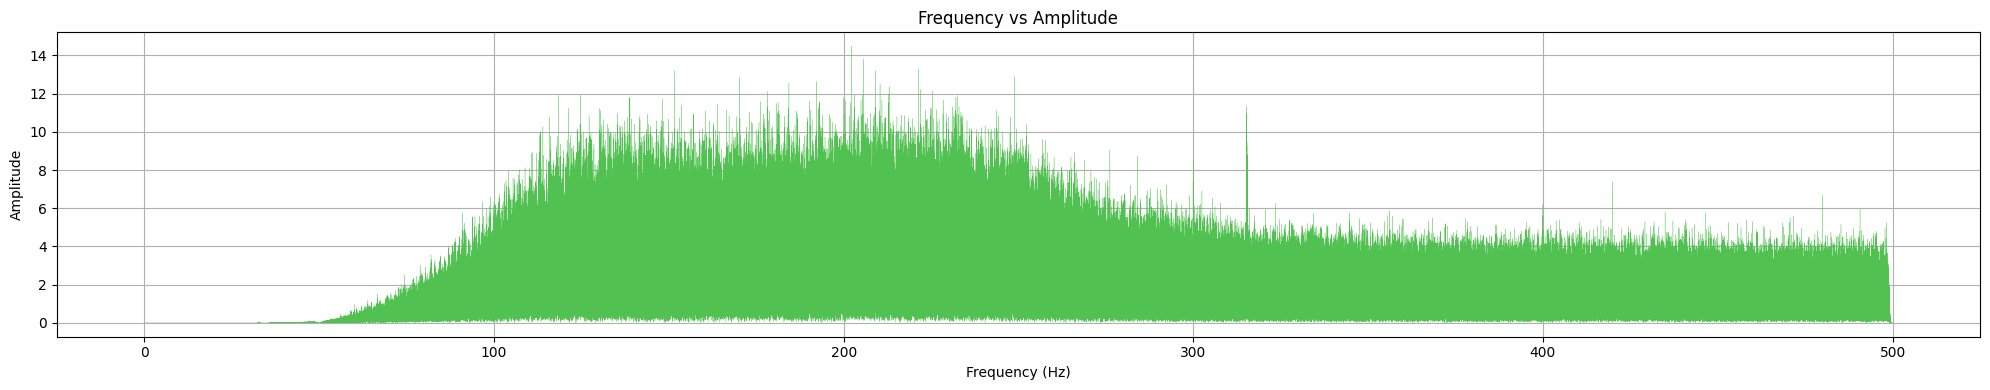

In [82]:
plt_save_path = gastric_compute_freq(df, save_dir)

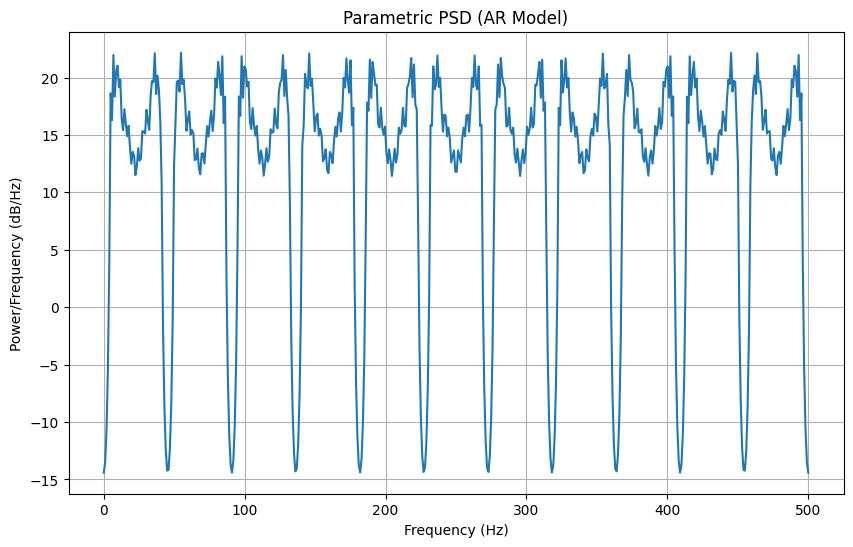

In [5]:
import numpy as np
from scipy.signal import lfilter
import matplotlib.pyplot as plt

# Assuming `signal_data` is a NumPy array
check_freq = notched_butter_demean_signal

# Define the AR model order
order = 14

# Estimate AR coefficients using the Yule-Walker equations
def estimate_ar_yw(signal, order):
    from scipy.linalg import toeplitz
    r = np.correlate(signal, signal, mode='full')  # Autocorrelation
    r = r[len(signal)-1:]  # Keep positive lags
    R = toeplitz(r[:order])  # Autocorrelation matrix
    r_vector = r[1:order+1]  # Right-hand side
    ar_coeffs = np.linalg.solve(R, r_vector)  # Solve for AR coefficients
    return np.hstack(([1], -ar_coeffs)), r[0]  # Include AR(0) term and variance

# Estimate AR coefficients
ar_coeffs, noise_variance = estimate_ar_yw(check_freq, order)

# Compute the PSD
def compute_psd(ar_coeffs, noise_variance, nfft, sampling_rate):
    freqs = np.linspace(0, sampling_rate/2, nfft//2)
    w = 2 * np.pi * freqs
    h = 1.0 / np.abs(np.polyval(ar_coeffs, np.exp(-1j * w)))  # AR transfer function
    psd = noise_variance * (h**2)  # Power spectrum
    return freqs, psd


sampling_rate = 1000  
nfft = 1024  # Number of FFT points for PSD

freqs, psd = compute_psd(ar_coeffs, noise_variance, nfft, sampling_rate)

# Plot the PSD
plt.figure(figsize=(10, 6))
plt.plot(freqs, 10 * np.log10(psd))  # Convert to dB scale
plt.title("Parametric PSD (AR Model)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power/Frequency (dB/Hz)")
plt.grid()
plt.show()


[0.00534 0.00427 0.00061 ... 0.00168 0.00259 0.00381]


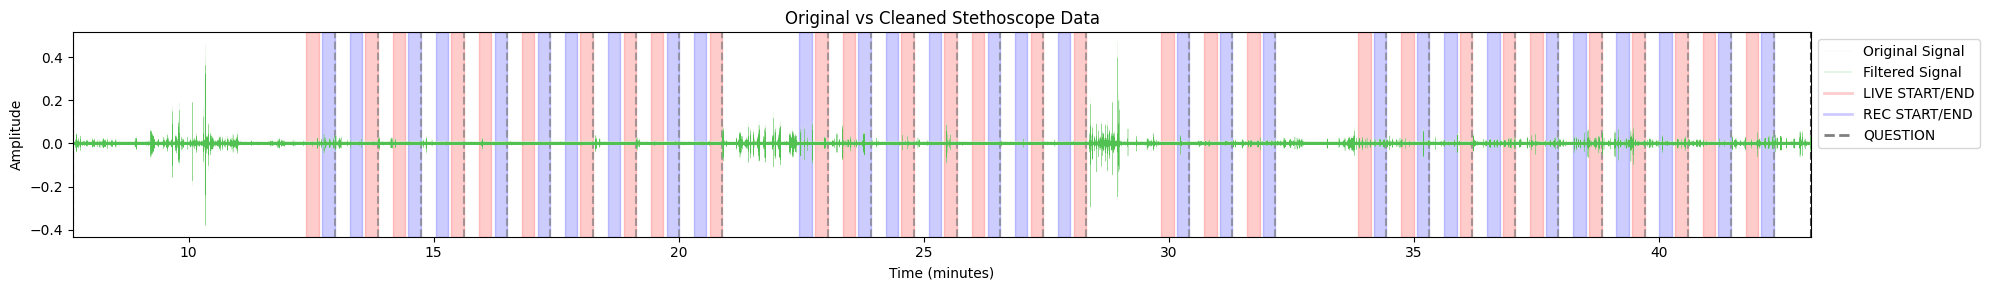

In [4]:
## SIGNAL IMPORT AND CLEANING ## 
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

#Requires: 
#channel_data_df[5] <-- vector of signal
#sample_rate = 1000 
#text_data_df = convert_text_data_to_time_string(text_data_df, channel=30)


signal_data = channel_data_df[5].values  # 5 = stethoscope
signal_data = signal_data[~np.isnan(signal_data)]  # Remove NaNs
# signal_data = signal_data * 1000  # Scaling if needed
sample_rate = 1000  # The sample rate of the signal
print(signal_data)

# Create time axis in seconds based on sample rate
time = np.arange(len(signal_data)) / sample_rate
time_mins = time/60

# Apply a notch filter at 50 Hz to remove mains interference
nyquist = 0.5 * sample_rate
notch_freq = 50.0
notch_w0 = notch_freq / nyquist
b_notch, a_notch = signal.iirnotch(notch_w0, Q=30)  # Quality factor of 30
notched_signal = signal.filtfilt(b_notch, a_notch, signal_data)

# Bandpass filter specifications (100 Hz to 500 Hz)
low = 100
high = 499


# Apply the bandpass filter
b, a = signal.butter(3, [low, high], btype='bandpass', fs=sample_rate, analog=False)
notched_butter_signal = signal.filtfilt(b, a, notched_signal)


# Remove the mean from the cleaned signal
notched_butter_demean_signal = notched_butter_signal - np.mean(notched_butter_signal)

## TASK MARKERS FOR PLOTTING
category_map = {
    'START TASK': 'task_start',
    'LIVE START': 'live_start_end',
    'LIVE END': 'live_start_end',
    'REC START': 'rec_start_end',
    'REC END': 'rec_start_end',
    'QUESTION': 'question',
    'START TASK': 'task_start',
    'END TASK': 'task_end',
}

color_map = {
    'live_start_end': 'red',
    'rec_start_end': 'blue',
    'question': 'grey',
    'task_start': 'black',  # Color for 'START TASK'
    'task_end': 'black',    # Color for 'END TASK'
}


# Update DataFrame with categories and colors
def assign_category_and_color(row):
    label = row['string']  # Use the 'string' column for matching

    # Match 'RECORDING_*' pattern dynamically
    if re.match(r'^RECORDING_\d+$', label):  # Matches 'RECORDING_0', 'RECORDING_30', etc.
        category = 'recording_*'
    else:
        category = category_map.get(label, 'other')  # Map based on category_map or default to 'other'

    color = color_map.get(category)  # Get color based on the category
    return category, color

# Apply function to DataFrame
text_data_df[['category', 'color']] = text_data_df.apply(
    lambda row: pd.Series(assign_category_and_color(row)), axis=1
)

# Filter out rows where category is 'other'
filtered_df = text_data_df[text_data_df['category'] != 'other']


# Initialize variables for shading
shading_intervals = {'live_start_end': [], 'rec_start_end': []}

# Identify intervals for shading (already existing)
start_markers = {'live_start_end': 'LIVE START', 'rec_start_end': 'REC START'}
end_markers = {'live_start_end': 'LIVE END', 'rec_start_end': 'REC END'}

for category, start_marker in start_markers.items():
    end_marker = end_markers[category]

    # Find start and end times for each category
    starts = filtered_df[filtered_df['string'] == start_marker]['time_hz'] / 60000
    ends = filtered_df[filtered_df['string'] == end_marker]['time_hz'] / 60000

    # Pair start and end times
    shading_intervals[category] = list(zip(starts, ends))

marker_positions = []

## PLOT
plt.figure(figsize=(20, 3))
plt.title('Original vs Cleaned Stethoscope Data')
plt.xlabel('Time (minutes)')
plt.ylabel('Amplitude')

# Add transparent shading for intervals
for category, intervals in shading_intervals.items():
    for start, end in intervals:
        plt.axvspan(start, end, color=color_map[category], alpha=0.2)  # Transparent shading
        marker_positions.extend([start, end])  # Add shading bounds to marker positions

# Add vertical lines for 'QUESTION' markers
question_rows = filtered_df[filtered_df['category'] == 'question']
for _, row in question_rows.iterrows():
    time_hz = row['time_hz'] / 60000  # Convert to minutes
    plt.axvline(x=time_hz, color=color_map['question'], linestyle='--', alpha=0.7, linewidth=1.5)
    marker_positions.append(time_hz)  # Add question marker positions to marker positions

# Add vertical lines for 'START TASK' and 'END TASK' markers
start_task_rows = filtered_df[filtered_df['category'] == 'task_start']
for _, row in start_task_rows.iterrows():
    time_hz = row['time_hz'] / 60000  # Convert to minutes
    plt.axvline(x=time_hz, color=color_map['task_start'], linestyle='--', alpha=0.7, linewidth=1.5)
    marker_positions.append(time_hz)  # Add task start marker positions to marker positions

end_task_rows = filtered_df[filtered_df['category'] == 'task_end']
for _, row in end_task_rows.iterrows():
    time_hz = row['time_hz'] / 60000  # Convert to minutes
    plt.axvline(x=time_hz, color=color_map['task_end'], linestyle='--', alpha=0.7, linewidth=1.5)
    marker_positions.append(time_hz)  # Add task end marker positions to marker positions

# Plot the original and cleaned signal
plt.plot(time_mins, signal_data, label='Original Signal', color='#ceebc7', alpha=0.6, lw = 0.2)
plt.plot(time_mins, notched_butter_demean_signal, label='Filtered Signal', color='#51C151', alpha=1.0, lw= 0.2)
plt.xlim(min(marker_positions), max(marker_positions))

# Custom legend
handles, labels = plt.gca().get_legend_handles_labels()
live_start_handle = plt.Line2D([0], [0], color='#fbcdcd', lw=2, label='LIVE START/END')
rec_start_handle = plt.Line2D([0], [0], color='#ceccfe', lw=2, label='REC START/END')
question_handle = plt.Line2D([0], [0], color='grey', linestyle='--', lw=2, label='QUESTION')
#task_start_handle = plt.Line2D([0], [0], color='purple', linestyle='--', lw=2, label='START TASK')
#task_end_handle = plt.Line2D([0], [0], color='orange', linestyle='--', lw=2, label='END TASK')

handles.extend([live_start_handle, rec_start_handle, question_handle])
labels.extend(['LIVE START/END', 'REC START/END', 'QUESTION'])

# Show legend
plt.legend(handles=handles, labels=labels, loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()




In [7]:
import os
import re

import numpy as np
import pandas as pd
import scipy
from scipy import io
from scipy import signal

from scipy.signal import stft
from scipy.stats import hmean
import matplotlib.pyplot as plt
from IPython.display import display, HTML

from preprocessing_functions import extract_participant_and_channel_info, \
    extract_channel_data_from_file, channel_data_to_df, \
    convert_text_data_to_time_string, plot_channels, plot_channels_markers
plt.ioff() #supress plots displaying

def gastric_stethoscope(signal_data, save_dir, figsize = (20,4), sample_rate = 1000, detailed_plots = False):
    
    try: 
        #signal_data = channel_data_df[5].values  # 5 = stethoscope
        signal_data = signal_data[~np.isnan(signal_data)]  # Remove NaNs

        # Create time axis in seconds based on sample rate
        time = np.arange(len(signal_data)) / sample_rate
        time_mins = time/60

        if detailed_plots: 
            # Plotting comparison: Original vs Cleaned signal
            plt.figure(figsize=(12, 3))
            plt.plot(time_mins, signal_data, label='Original Signal', color='#ceebc7', alpha=0.8,lw = 0.2)  # Original signal with transparency
            plt.title('Original Signal')
            plt.xlabel('Time (minutes)')
            plt.ylabel('Amplitude')
            plt.legend()
            plt.tight_layout()
            plt.show()

        # Apply a notch filter at 50 Hz to remove mains interference
        nyquist = 0.5 * sample_rate
        notch_freq = 50.0
        notch_w0 = notch_freq / nyquist
        b_notch, a_notch = signal.iirnotch(notch_w0, Q=30)  # Quality factor of 30
        notched_signal = signal.filtfilt(b_notch, a_notch, signal_data)

        if detailed_plots: 
        # Plotting comparison: Original vs Notch filtered signal
            plt.figure(figsize=(12, 3))
            plt.plot(time_mins, signal_data, label='Original Signal', color='#ceebc7', alpha=0.8)  # Original signal with transparency
            plt.plot(time_mins, notched_signal, label='Notch filtered', color='#51C151', alpha=0.8, lw = 0.2)  
            plt.title('Original vs Notch filtered Signal')
            plt.xlabel('Time (seconds)')
            plt.ylabel('Amplitude')
            plt.legend()
            plt.tight_layout()
            plt.show()



        # Bandpass filter specifications (100 Hz to 500 Hz)
        low = 100
        high = 499
        b, a = signal.butter(3, [low, high], btype='bandpass', fs=sample_rate, analog=False)
        notched_butter_signal = signal.filtfilt(b, a, notched_signal)

        if detailed_plots: 
        # Plotting comparison: Original vs  Notch+100_499BP filtered signal
            plt.figure(figsize=(12, 3))
            plt.plot(time_mins, signal_data, label='Original Signal', color='#ceebc7', alpha=0.8)  # Original signal with transparency
            plt.plot(time_mins, notched_butter_signal, label='Notch+100_499BP filtered', color='#51C151', alpha=0.8, lw = 0.2)  
            plt.title('Original vs Notch+100_499BP filtered Signal')
            plt.xlabel('Time (minutes)')
            #plt.ylim(-0.001, 0.001)
            plt.ylabel('Amplitude')
            plt.legend()
            plt.tight_layout()
            plt.show()


        # Remove the mean from the cleaned signal
        notched_butter_demean_signal = notched_butter_signal - np.mean(notched_butter_signal)
        
        if detailed_plots: 
        # Plotting comparison: Original vs Cleaned signal
            plt.figure(figsize=(12, 3))
            plt.plot(time_mins, signal_data, label='Original Signal', color='#ceebc7', alpha=0.8, )  # Original signal with transparency
            plt.plot(time_mins, notched_butter_demean_signal, label='Original Signal', color='#51C151', alpha=0.8, lw = 0.2)  
            plt.title('Original vs Notch+100_499BP_demean filtered Signal')
            plt.xlabel('Time (minutes)')
            plt.ylabel('Amplitude')
            plt.legend()
            plt.tight_layout()
            plt.show()

        ## TASK MARKERS FOR PLOTTING
        category_map = {
            'START TASK': 'task_start',
            'LIVE START': 'live_start_end',
            'LIVE END': 'live_start_end',
            'REC START': 'rec_start_end',
            'REC END': 'rec_start_end',
            'QUESTION': 'question',
            'START TASK': 'task_start',
            'END TASK': 'task_end',
        }

        color_map = {
            'live_start_end': 'red',
            'rec_start_end': 'blue',
            'question': 'grey',
            'task_start': 'black',  # Color for 'START TASK'
            'task_end': 'black',    # Color for 'END TASK'
        }


        # Update DataFrame with categories and colors
        def assign_category_and_color(row):
            label = row['string']  # Use the 'string' column for matching

            # Match 'RECORDING_*' pattern dynamically
            if re.match(r'^RECORDING_\d+$', label):  # Matches 'RECORDING_0', 'RECORDING_30', etc.
                category = 'recording_*'
            else:
                category = category_map.get(label, 'other')  # Map based on category_map or default to 'other'

            color = color_map.get(category)  # Get color based on the category
            return category, color

        # Apply function to DataFrame
        text_data_df[['category', 'color']] = text_data_df.apply(
            lambda row: pd.Series(assign_category_and_color(row)), axis=1
        )

        # Filter out rows where category is 'other'
        filtered_df = text_data_df[text_data_df['category'] != 'other']


        # Initialize variables for shading
        shading_intervals = {'live_start_end': [], 'rec_start_end': []}

        # Identify intervals for shading (already existing)
        start_markers = {'live_start_end': 'LIVE START', 'rec_start_end': 'REC START'}
        end_markers = {'live_start_end': 'LIVE END', 'rec_start_end': 'REC END'}

        for category, start_marker in start_markers.items():
            end_marker = end_markers[category]

            # Find start and end times for each category
            starts = filtered_df[filtered_df['string'] == start_marker]['time_hz'] / 60000
            ends = filtered_df[filtered_df['string'] == end_marker]['time_hz'] / 60000

            # Pair start and end times
            shading_intervals[category] = list(zip(starts, ends))

        marker_positions = []

        ## PLOT
        plt.figure(figsize=figsize)
        plt.title('Original vs Cleaned Stethoscope Data')
        plt.xlabel('Time (minutes)')
        plt.ylabel('Amplitude')

        # Add transparent shading for intervals
        for category, intervals in shading_intervals.items():
            for start, end in intervals:
                plt.axvspan(start, end, color=color_map[category], alpha=0.2)  # Transparent shading
                marker_positions.extend([start, end])  # Add shading bounds to marker positions

        # Add vertical lines for 'QUESTION' markers
        question_rows = filtered_df[filtered_df['category'] == 'question']
        for _, row in question_rows.iterrows():
            time_hz = row['time_hz'] / 60000  # Convert to minutes
            plt.axvline(x=time_hz, color=color_map['question'], linestyle='--', alpha=0.7, linewidth=1.5)
            marker_positions.append(time_hz)  # Add question marker positions to marker positions

        # Add vertical lines for 'START TASK' and 'END TASK' markers
        start_task_rows = filtered_df[filtered_df['category'] == 'task_start']
        for _, row in start_task_rows.iterrows():
            time_hz = row['time_hz'] / 60000  # Convert to minutes
            plt.axvline(x=time_hz, color=color_map['task_start'], linestyle='--', alpha=0.7, linewidth=1.5)
            marker_positions.append(time_hz)  # Add task start marker positions to marker positions

        end_task_rows = filtered_df[filtered_df['category'] == 'task_end']
        for _, row in end_task_rows.iterrows():
            time_hz = row['time_hz'] / 60000  # Convert to minutes
            plt.axvline(x=time_hz, color=color_map['task_end'], linestyle='--', alpha=0.7, linewidth=1.5)
            marker_positions.append(time_hz)  # Add task end marker positions to marker positions

        # Plot the original and cleaned signal
        plt.plot(time_mins, signal_data, label='Original Signal', color='#ceebc7', alpha=0.6, lw = 0.2)
        plt.plot(time_mins, notched_butter_demean_signal, label='Filtered Signal', color='#51C151', alpha=1.0, lw= 0.2)
        plt.xlim(min(marker_positions), max(marker_positions))

        # Custom legend
        handles, labels = plt.gca().get_legend_handles_labels()
        live_start_handle = plt.Line2D([0], [0], color='#fbcdcd', lw=2, label='LIVE START/END')
        rec_start_handle = plt.Line2D([0], [0], color='#ceccfe', lw=2, label='REC START/END')
        question_handle = plt.Line2D([0], [0], color='grey', linestyle='--', lw=2, label='QUESTION')
        #task_start_handle = plt.Line2D([0], [0], color='purple', linestyle='--', lw=2, label='START TASK')
        #task_end_handle = plt.Line2D([0], [0], color='orange', linestyle='--', lw=2, label='END TASK')

        handles.extend([live_start_handle, rec_start_handle, question_handle])
        labels.extend(['LIVE START/END', 'REC START/END', 'QUESTION'])

        # Show legend
        plt.legend(handles=handles, labels=labels, loc='upper left', bbox_to_anchor=(1, 1))


        plt_name = 'GASTRIC_stethoscope.png'
        plt_save_path = save_dir + '/'+ plt_name
        plt.savefig(plt_save_path, dpi=300, bbox_inches='tight')
        plt.tight_layout()
        #plt.show()

        return plt_save_path, plt_freq_save_path
    
    except Exception as e:
        # Handle exception and create fallback image
        print(f"An error occurred: {e}")
        
        plt_name = 'GASTRIC_stethoscope.png'

        # Create FAILED figure with green shading
        plt.figure(figsize=figsize, facecolor='white')
        plt.gca().set_facecolor('white')
        plt.text(0.5, 0.5, f"Data to produce {plt_name} not found",
                 fontsize=14, ha='center', va='center', color='#ceebc7')

        # Save the fallback image
        fallback_path = 'GASTRIC_stethoscope_FAIL_image.png'
        plt_save_path = save_dir +  '/' + fallback_path
        plt.axis('off') 
        plt.savefig(plt_save_path, bbox_inches='tight', facecolor='white')
    
        return plt_save_path 